# Module 06, Part 3: Scale and the memory bill

This notebook is the runnable companion to Part 3 of the Module 06 learning content.
It checks, with code:

1. The compute rule $C \approx 6ND$ and the table of pretraining times.
2. The memory rule for fine-tuning with Adam, **16 bytes per parameter**, by measuring
   the tensors a real training step keeps alive.
3. That optimizer state exists only for the parameters that are trained, which is why
   parameter-efficient methods save memory.
4. The memory table for a model with 7 billion parameters under full fine-tuning, LoRA
   and QLoRA.

Memory figures here count weights, gradients and optimizer states. They leave out
activations, which grow with batch size and sequence length. Nothing here needs a GPU.

In [9]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

torch.manual_seed(0)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.15.0+cpu


## 1. Compute: $C \approx 6ND$

A forward pass costs about 2 floating-point operations per parameter per token, and the
backward pass about 4, so one pass over $D$ tokens costs $6ND$. The rule of thumb of
about 20 training tokens per parameter turns the model size into a token count. The
table assumes one GPU that sustains 100 teraFLOP/s, which is generous for a single card.

In [10]:
GB = 1e9


def compute_flops(n_params, n_tokens):
    """About 6 floating-point operations per parameter per token (2 forward, 4 backward)."""
    return 6.0 * n_params * n_tokens


def training_time_seconds(n_params, n_tokens, flops_per_second=100e12):
    return compute_flops(n_params, n_tokens) / flops_per_second


def full_finetune_bytes(n_params):
    """Adam in mixed precision: 2 (weights) + 2 (grads) + 4 (fp32 master) + 4 + 4 (Adam moments)."""
    return 16 * n_params


def lora_params(n_layers, width, rank, matrices_per_layer=4):
    """Trainable parameters when every adapted matrix is width x width."""
    return n_layers * matrices_per_layer * rank * (width + width)


def lora_bytes(n_params, n_trainable, weight_bytes=2.0, block=None, scale_bytes=4):
    """Frozen base stored at weight_bytes per weight, plus 16 bytes per trainable parameter.

    If block is given, add one scale of scale_bytes for every block of weights.
    """
    base = weight_bytes * n_params
    if block:
        base += scale_bytes * n_params / block
    return base + 16 * n_trainable

In [11]:
print(f"{'parameters':>12s}{'tokens (20 per param)':>24s}{'compute 6ND':>14s}{'time on one GPU':>20s}")
for n in (125e6, 1.3e9, 7e9, 70e9):
    d = 20 * n
    secs = training_time_seconds(n, d)
    if secs < 86400:
        t = f"{secs / 3600:.1f} hours"
    elif secs < 365 * 86400:
        t = f"{secs / 86400:.1f} days"
    else:
        t = f"{secs / (365 * 86400):.1f} years"
    print(f"{n:12.3g}{d:24.3g}{compute_flops(n, d):14.2e}{t:>20s}")

  parameters   tokens (20 per param)   compute 6ND     time on one GPU
    1.25e+08                 2.5e+09      1.88e+18           5.2 hours
     1.3e+09                 2.6e+10      2.03e+20           23.5 days
       7e+09                 1.4e+11      5.88e+21           1.9 years
       7e+10                 1.4e+12      5.88e+23         186.5 years


Cost grows with the square of the model size, because the data grows with it. The small
end fits on one machine. The 70 billion row would take about 190 years on that one GPU,
which is why real runs use thousands of GPUs at once. The 20-tokens-per-parameter figure
is a rule of thumb from particular experiments, and models that will be served heavily
are now often trained on far more tokens.

## 2. Memory: 16 bytes per parameter

Training with Adam keeps, for every parameter, its weight, its gradient and two running
averages. In plain 32-bit training that is $4 + 4 + 4 + 4 = 16$ bytes. In mixed
precision the weights and gradients are 16-bit (2 + 2) but a 32-bit master copy (4) is
kept next to the two 32-bit Adam averages (4 + 4), which is again 16.

We **measure** it. Build a network, run three training steps, and add up the bytes of
every tensor that Adam is keeping.

In [12]:
def tensor_bytes(t):
    return t.numel() * t.element_size()

def training_state_bytes(model, optimizer):
    """Bytes of weights, gradients and Adam state, summed from the real tensors."""
    w = sum(tensor_bytes(p) for p in model.parameters())
    g = sum(tensor_bytes(p.grad) for p in model.parameters() if p.grad is not None)
    s = sum(tensor_bytes(t) for st in optimizer.state.values() for t in st.values() if torch.is_tensor(t) and t.dim() > 0)
    return w, g, s

net = nn.Sequential(nn.Linear(512, 2048), nn.ReLU(), nn.Linear(2048, 2048), nn.ReLU(), nn.Linear(2048, 512))
n_params = sum(p.numel() for p in net.parameters())
opt = torch.optim.Adam(net.parameters(), 1e-3)
for _ in range(3):
    loss = net(torch.randn(8, 512)).pow(2).mean()
    opt.zero_grad(); loss.backward(); opt.step()

w, g, s = training_state_bytes(net, opt)
print(f"parameters: {n_params:,}")
print(f"weights {w / n_params:.1f} bytes/param, gradients {g / n_params:.1f}, Adam state {s / n_params:.1f}")
print(f"total {(w + g + s) / n_params:.1f} bytes per parameter in 32-bit training")
assert abs((w + g + s) / n_params - 16) < 0.01
print()
print("Mixed precision accounting, in bytes per parameter:")
print("  16-bit weights 2, 16-bit gradients 2, 32-bit master copy 4, two 32-bit Adam averages 8 =", 2 + 2 + 4 + 8)
print(f"  budget.full_finetune_bytes(1) = {full_finetune_bytes(1)}")

parameters: 6,296,064
weights 4.0 bytes/param, gradients 4.0, Adam state 8.0
total 16.0 bytes per parameter in 32-bit training

Mixed precision accounting, in bytes per parameter:
  16-bit weights 2, 16-bit gradients 2, 32-bit master copy 4, two 32-bit Adam averages 8 = 16
  budget.full_finetune_bytes(1) = 16


Both ways of counting give 16 bytes per parameter. For a model with 7 billion
parameters that is 112 GB before a single activation, against about 16 GB on a free
GPU session. The number of bytes per weight is the lever the next two parts pull.

## 3. Optimizer state exists only for trained parameters

If most parameters are frozen, they need no gradient and no Adam state. We freeze all
but a small head and repeat the measurement.

In [13]:
net2 = nn.Sequential(nn.Linear(512, 2048), nn.ReLU(), nn.Linear(2048, 2048), nn.ReLU(), nn.Linear(2048, 512))
for p in net2[:-1].parameters():
    p.requires_grad_(False)                    # freeze everything except the last layer
trainable = [p for p in net2.parameters() if p.requires_grad]
n_train = sum(p.numel() for p in trainable)
opt2 = torch.optim.Adam(trainable, 1e-3)
for _ in range(3):
    loss = net2(torch.randn(8, 512)).pow(2).mean()
    opt2.zero_grad(); loss.backward(); opt2.step()

w2, g2, s2 = training_state_bytes(net2, opt2)
print(f"trainable parameters: {n_train:,} of {n_params:,} ({100 * n_train / n_params:.1f}%)")
print(f"gradients + Adam state: {(g2 + s2) / 1e6:.1f} MB, against {(g + s) / 1e6:.1f} MB when everything is trained")
print(f"gradients + Adam state per trainable parameter: {(g2 + s2) / n_train:.1f} bytes")

trainable parameters: 1,049,088 of 6,296,064 (16.7%)
gradients + Adam state: 12.6 MB, against 75.6 MB when everything is trained
gradients + Adam state per trainable parameter: 12.0 bytes


Gradient and optimizer memory scales with the **trained** parameters, 12 bytes each in
this 32-bit run. The frozen weights still have to be stored, and activations still flow
through every layer, so the saving is real but not total. LoRA, in Part 4, uses exactly
this: it freezes the pretrained weights and trains a small number of added ones.

## 4. A 7 billion parameter model under three methods

Bytes per weight, the memory of the weights alone:

In [14]:
N = 7e9
print(f"{'format':28s}{'bytes per weight':>18s}{'weights of a 7B model':>24s}")
for name, b in (("32-bit float", 4), ("16-bit float (fp16 or bf16)", 2), ("8-bit integer", 1), ("4-bit integer", 0.5)):
    print(f"{name:28s}{b:18.1f}{b * N / GB:21.1f} GB")

format                        bytes per weight   weights of a 7B model
32-bit float                               4.0                 28.0 GB
16-bit float (fp16 or bf16)                2.0                 14.0 GB
8-bit integer                              1.0                  7.0 GB
4-bit integer                              0.5                  3.5 GB


Now the full bill. LoRA at rank 16 on the four attention projections of 32 layers of
width 4096 trains 16.8 million parameters. QLoRA stores the frozen base in 4 bits, with
one 32-bit scale for every block of 64 weights (an extra half bit per weight).

trainable LoRA parameters: 16,777,216 (0.24% of the model)
method                       total, before activations
Full fine-tuning                              112.0 GB
LoRA on a 16-bit base                          14.3 GB
QLoRA on a 4-bit base                           4.2 GB


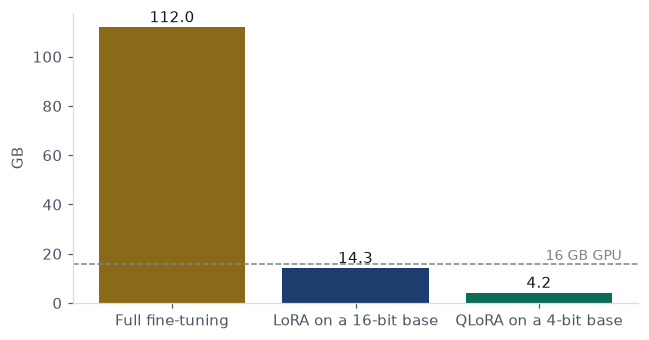

In [15]:
n_lora = lora_params(n_layers=32, width=4096, rank=16)
rows = {
    "Full fine-tuning": full_finetune_bytes(N),
    "LoRA on a 16-bit base": lora_bytes(N, n_lora, weight_bytes=2.0),
    "QLoRA on a 4-bit base": lora_bytes(N, n_lora, weight_bytes=0.5, block=64),
}
print(f"trainable LoRA parameters: {n_lora:,} ({100 * n_lora / N:.2f}% of the model)")
print(f"{'method':26s}{'total, before activations':>28s}")
for name, b in rows.items():
    print(f"{name:26s}{b / GB:25.1f} GB")
assert [round(b / GB, 1) for b in rows.values()] == [112.0, 14.3, 4.2]

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(list(rows), [b / GB for b in rows.values()], color=[AMBER, NAVY, GREEN])
ax.axhline(16, color=MUTED, lw=1, ls="--"); ax.text(2.45, 17.5, "16 GB GPU", ha="right", color=MUTED, fontsize=9)
ax.set_ylabel("GB"); ax.grid(False)
for i, b in enumerate(rows.values()):
    ax.text(i, b / GB + 2, f"{b / GB:.1f}", ha="center", color=INK)
plt.tight_layout(); plt.show()

Under this accounting the same model needs 112 GB to fine-tune fully and about 4 GB with
QLoRA, which is a different category of hardware. Three honest limits apply to every
number here: activations are not counted, the figures assume the 16-bit and 4-bit
formats described, and a real run has framework overhead on top.

On a GPU you would read the real peak, which is the number to report:

In [16]:
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
    big = nn.Sequential(nn.Linear(4096, 4096), nn.ReLU(), nn.Linear(4096, 4096)).cuda()
    o = torch.optim.Adam(big.parameters(), 1e-3)
    big(torch.randn(16, 4096, device="cuda")).sum().backward(); o.step()
    print(f"peak allocated: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB (nvidia-smi will show more)")
else:
    print("No GPU here. On a GPU, report torch.cuda.max_memory_allocated() with the batch size and sequence length.")

No GPU here. On a GPU, report torch.cuda.max_memory_allocated() with the batch size and sequence length.


## Try it

1. Write a function that takes a parameter count and returns the training memory in GB
   for full fine-tuning with Adam in mixed precision. Check it against the table.
2. Count the parameters of a small pretrained model of your choice, and predict the
   memory for fine-tuning and for inference alone.
3. In section 2, switch the optimizer to SGD with momentum. How many bytes per parameter
   does the optimizer state use now?
4. Change the rank in section 4 to 4 and to 64. How much does the QLoRA total change?
   Which term dominates the total?

## What this notebook showed

- Compute is about $6ND$, and the cost of pretraining grows with the square of the model
  size once the data grows with it.
- Fine-tuning with Adam keeps 16 bytes per parameter, measured and not just asserted.
- Gradients and optimizer states exist only for the parameters being trained.
- Storing the frozen base in fewer bits is the second lever, and it is the subject of
  Part 5.